# Fashion-MNIST: SimpleCNN vs DeepCNN benchmark

**Krishna Gehlot · Milestone 2.2 · Team T112**
*Project 11: Inventory Image Tagging via Handcrafted Features and Deep Learning*

Main CNN benchmark for Phase 2. The two from-scratch architectures in `src/dl/models/cnn.py` are trained with the shared engine in `src/dl/training.py` and compared against the Phase 1 AML baselines.

| Model | Conv blocks | Feature map before head | Head |
|:---|:---:|:---:|:---|
| `SimpleCNN` | 2 (32, 64 channels) | $64 \times 7 \times 7$ | `Linear(3136, 128)` → `Linear(128, 10)` |
| `DeepCNN` | 3 (32, 64, 128 channels) | $128 \times 3 \times 3$ | `Linear(1152, 256)` → `Linear(256, 10)` |

**Protocol (identical for both models):**
1. Train on the stratified 48,000-image split with augmentation (horizontal flip, $\pm 10^\circ$ rotation), batch size 128, seed 42.
2. Adam ($lr = 10^{-3}$, weight decay $10^{-4}$), `ReduceLROnPlateau`, at most 30 epochs, early stopping on **validation Macro F1** with patience 5. The best-epoch weights are restored.
3. Evaluate once on the official 10,000-image test set and export a result record to `phase2_reports/results/`.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file() and (p / "src" / "dl").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or notebooks/ directory.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.data import CLASS_NAMES
from dl.data import get_dataloaders
from dl.models.cnn import DeepCNN, SimpleCNN, count_parameters
from dl.training import evaluate_model, fit_model, make_result_record

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 5
SHIRT = CLASS_NAMES.index("Shirt")

RESULTS_DIR = ROOT / "phase2_reports" / "results"
FIGURES_DIR = ROOT / "phase2_reports" / "figures"
PHASE1_RESULTS_DIR = ROOT / "reports" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.15.0 | device: mps


## 1. Training helpers

`fit_model()` records training loss, training accuracy, validation accuracy and validation Macro F1, but not validation loss. To plot training vs. validation loss without changing the shared engine, `ValLossRecorder` wraps the validation loader and reads the model's logits through a forward hook during each validation pass.

Note that the two loss curves are measured differently: training loss is averaged over an epoch with dropout active and on augmented images, while validation loss uses the end-of-epoch weights in eval mode on unaugmented images. Validation loss below training loss is therefore expected for a regularized model.

In [2]:
class ValLossRecorder:
    """Wrap a validation loader and record mean cross-entropy per full pass."""

    def __init__(self, loader, model):
        self.loader = loader
        self.losses = []
        self._labels = None
        self._sum = 0.0
        self._count = 0
        self._hook = model.register_forward_hook(self._on_forward)

    def _on_forward(self, module, inputs, logits):
        if module.training or self._labels is None:
            return
        loss = F.cross_entropy(logits.detach().cpu(), self._labels, reduction="sum")
        self._sum += loss.item()
        self._count += len(self._labels)
        self._labels = None

    def __iter__(self):
        self._sum, self._count = 0.0, 0
        for images, labels in self.loader:
            self._labels = labels
            yield images, labels
        self._labels = None
        self.losses.append(self._sum / self._count)

    def __len__(self):
        return len(self.loader)

    def close(self):
        self._hook.remove()


def measure_latency_ms(model, loader, device, n_iterations=5):
    """Median per-image inference time (ms) for batched prediction on the test set."""
    model.eval()
    batches = [images.to(device) for images, _ in loader]
    n_images = sum(len(b) for b in batches)

    def run():
        with torch.no_grad():
            for batch in batches:
                model(batch).argmax(dim=1).cpu()  # .cpu() forces the device to finish

    run()  # warm-up
    times = []
    for _ in range(n_iterations):
        start = time.perf_counter()
        run()
        times.append((time.perf_counter() - start) / n_images)
    return float(np.median(times) * 1000.0)


def run_experiment(name, model_cls):
    """Train one architecture, evaluate it on the test set, and return everything."""
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    model = model_cls()
    # get_dataloaders re-seeds torch, so both models see the same batch order.
    train_loader, val_loader, test_loader = get_dataloaders(
        batch_size=BATCH_SIZE, data_dir=ROOT / "data" / "raw", seed=SEED,
    )

    recorder = ValLossRecorder(val_loader, model)
    history = fit_model(
        model, train_loader, recorder,
        epochs=MAX_EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, patience=PATIENCE,
        device=DEVICE,
    )
    recorder.close()
    history["val_loss"] = recorder.losses

    test_metrics = evaluate_model(model, test_loader, DEVICE)
    record = make_result_record(
        model_name=name,
        test_metrics=test_metrics,
        history=history,
        best_params={
            "architecture": model_cls.__name__,
            "optimizer": "Adam",
            "lr": LR,
            "weight_decay": WEIGHT_DECAY,
            "batch_size": BATCH_SIZE,
            "max_epochs": MAX_EPOCHS,
            "epochs_trained": len(history["train_loss"]),
            "early_stopping_patience": PATIENCE,
            "augmentation": "RandomHorizontalFlip(0.5) + RandomRotation(10)",
            "seed": SEED,
            "device": str(DEVICE),
        },
        train_n=len(train_loader.dataset),
        val_n=len(val_loader.dataset),
        test_n=len(test_loader.dataset),
        inference_latency_ms=measure_latency_ms(model, test_loader, DEVICE),
        parameter_count=count_parameters(model),
    )
    record["history"] = {
        key: history[key]
        for key in ("train_loss", "val_loss", "train_accuracy", "val_accuracy", "val_macro_f1")
    }
    return {"model": model, "history": history, "record": record}

## 2. Train SimpleCNN (2 blocks)

In [3]:
experiments = {}
experiments["cnn_simple"] = run_experiment("cnn_simple", SimpleCNN)

Training on device: mps


Epoch   1/30 | Loss: 0.7355 | Train Acc: 0.7333 | Val Acc: 0.8428 | Val F1: 0.8390 | LR: 0.001000 ← best


Epoch   2/30 | Loss: 0.5443 | Train Acc: 0.8020 | Val Acc: 0.8635 | Val F1: 0.8587 | LR: 0.001000 ← best


Epoch   3/30 | Loss: 0.4884 | Train Acc: 0.8210 | Val Acc: 0.8718 | Val F1: 0.8698 | LR: 0.001000 ← best


Epoch   4/30 | Loss: 0.4629 | Train Acc: 0.8334 | Val Acc: 0.8722 | Val F1: 0.8724 | LR: 0.001000 ← best


Epoch   5/30 | Loss: 0.4384 | Train Acc: 0.8409 | Val Acc: 0.8888 | Val F1: 0.8873 | LR: 0.001000 ← best


... (21 outputs left out)

Epoch  27/30 | Loss: 0.3125 | Train Acc: 0.8878 | Val Acc: 0.9199 | Val F1: 0.9199 | LR: 0.001000


Epoch  28/30 | Loss: 0.3113 | Train Acc: 0.8859 | Val Acc: 0.9174 | Val F1: 0.9156 | LR: 0.001000


Epoch  29/30 | Loss: 0.3110 | Train Acc: 0.8864 | Val Acc: 0.9183 | Val F1: 0.9175 | LR: 0.001000


Epoch  30/30 | Loss: 0.3059 | Train Acc: 0.8884 | Val Acc: 0.9186 | Val F1: 0.9176 | LR: 0.000500

Training complete. Best Val Macro F1: 0.9208 at epoch 26. Total time: 238.7s


## 3. Train DeepCNN (3 blocks)

In [4]:
experiments["cnn_deep"] = run_experiment("cnn_deep", DeepCNN)

Training on device: mps


Epoch   1/30 | Loss: 0.7105 | Train Acc: 0.7419 | Val Acc: 0.8508 | Val F1: 0.8467 | LR: 0.001000 ← best


Epoch   2/30 | Loss: 0.4852 | Train Acc: 0.8203 | Val Acc: 0.8684 | Val F1: 0.8635 | LR: 0.001000 ← best


Epoch   3/30 | Loss: 0.4299 | Train Acc: 0.8421 | Val Acc: 0.8750 | Val F1: 0.8747 | LR: 0.001000 ← best


Epoch   4/30 | Loss: 0.4020 | Train Acc: 0.8529 | Val Acc: 0.8870 | Val F1: 0.8878 | LR: 0.001000 ← best


Epoch   5/30 | Loss: 0.3807 | Train Acc: 0.8622 | Val Acc: 0.8939 | Val F1: 0.8917 | LR: 0.001000 ← best


... (21 outputs left out)

Epoch  27/30 | Loss: 0.2709 | Train Acc: 0.9021 | Val Acc: 0.9243 | Val F1: 0.9237 | LR: 0.000500


Epoch  28/30 | Loss: 0.2520 | Train Acc: 0.9079 | Val Acc: 0.9302 | Val F1: 0.9296 | LR: 0.000500 ← best


Epoch  29/30 | Loss: 0.2482 | Train Acc: 0.9106 | Val Acc: 0.9303 | Val F1: 0.9302 | LR: 0.000500 ← best


Epoch  30/30 | Loss: 0.2485 | Train Acc: 0.9089 | Val Acc: 0.9300 | Val F1: 0.9296 | LR: 0.000500

Training complete. Best Val Macro F1: 0.9302 at epoch 29. Total time: 258.0s


## 4. Training curves

Left: training vs. validation cross-entropy loss. Right: validation Macro F1 with training and validation accuracy. The dotted vertical line marks the best epoch, whose weights are the ones evaluated on the test set.

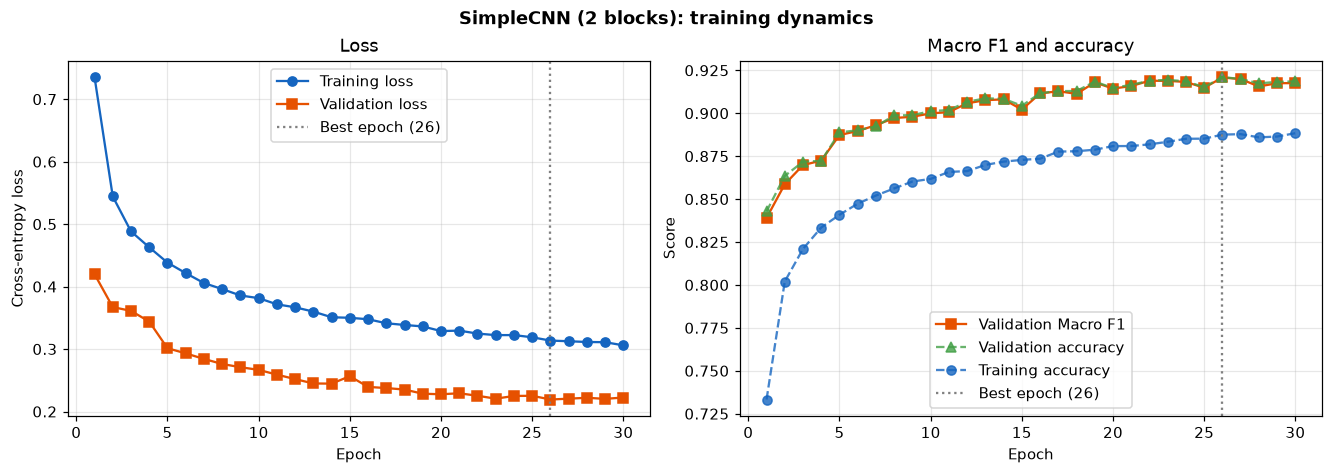

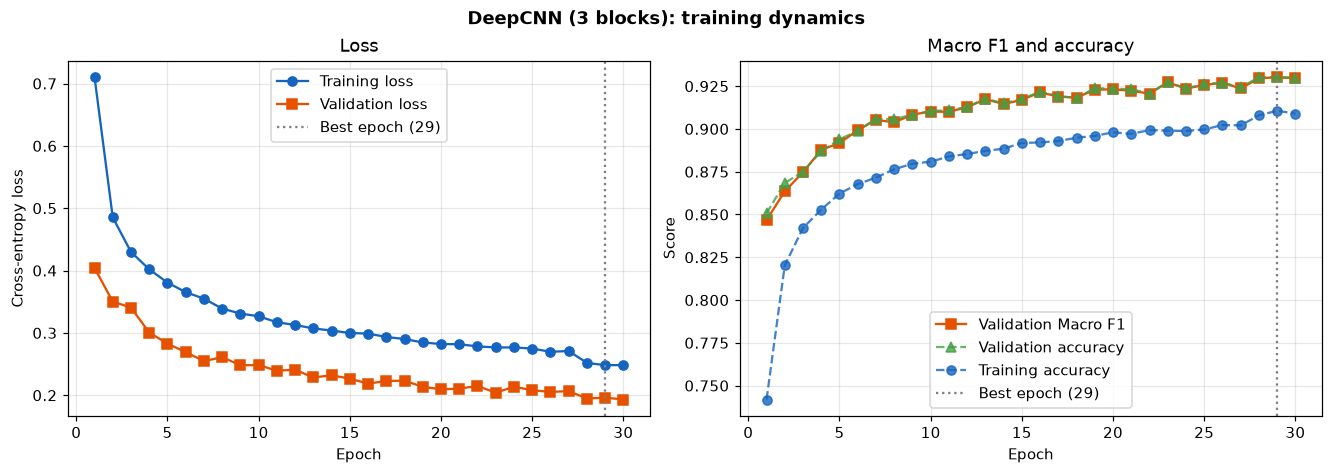

In [5]:
TITLES = {"cnn_simple": "SimpleCNN (2 blocks)", "cnn_deep": "DeepCNN (3 blocks)"}


def plot_training_curves(name, history, path):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    best = history["best_epoch"] + 1
    fig, (ax_loss, ax_score) = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

    ax_loss.plot(epochs, history["train_loss"], "o-", color="#1565C0", label="Training loss")
    ax_loss.plot(epochs, history["val_loss"], "s-", color="#E65100", label="Validation loss")
    ax_loss.set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")

    ax_score.plot(epochs, history["val_macro_f1"], "s-", color="#E65100", label="Validation Macro F1")
    ax_score.plot(epochs, history["val_accuracy"], "^--", color="#43A047", alpha=0.8, label="Validation accuracy")
    ax_score.plot(epochs, history["train_accuracy"], "o--", color="#1565C0", alpha=0.8, label="Training accuracy")
    ax_score.set(xlabel="Epoch", ylabel="Score", title="Macro F1 and accuracy")

    for ax in (ax_loss, ax_score):
        ax.axvline(best, color="gray", linestyle=":", label=f"Best epoch ({best})")
        ax.legend()
    fig.suptitle(f"{TITLES[name]}: training dynamics", fontweight="bold")
    fig.savefig(path, bbox_inches="tight")
    plt.show()


for name, short in (("cnn_simple", "simple"), ("cnn_deep", "deep")):
    plot_training_curves(name, experiments[name]["history"], FIGURES_DIR / f"training_curves_{short}.png")

## 5. Held-out test results

Each model is evaluated once on the official 10,000-image test set. Phase 1 AML results are loaded from `reports/results/` for reference.

In [6]:
def summary_row(label, rec):
    return {
        "Model": label,
        "Parameters": rec.get("parameter_count"),
        "Test accuracy": rec["test_accuracy"],
        "Test Macro F1": rec["test_macro_f1"],
        "Shirt recall": rec["per_class_recall"][SHIRT],
        "Latency (ms/img)": rec.get("inference_latency_ms_per_image"),
    }


rows = []
for path in sorted(PHASE1_RESULTS_DIR.glob("*.json")):
    rec = json.loads(path.read_text())
    rows.append(summary_row(f"Phase 1: {rec['model']} ({rec['features']})", rec))
for name, exp in experiments.items():
    rows.append(summary_row(f"Phase 2: {TITLES[name]}", exp["record"]))

summary = pd.DataFrame(rows).set_index("Model")
display(summary.style.format({
    "Parameters": lambda v: "n/a" if pd.isna(v) else f"{int(v):,}",
    "Test accuracy": "{:.2%}", "Test Macro F1": "{:.2%}", "Shirt recall": "{:.2%}",
    "Latency (ms/img)": "{:.4f}",
}))

training = pd.DataFrame({
    TITLES[name]: {
        "Epochs trained": exp["record"]["best_params"]["epochs_trained"],
        "Best epoch": exp["record"]["best_epoch"],
        "Stopped early": exp["record"]["stopped_early"],
        "Best val Macro F1": f"{exp['record']['best_val_macro_f1']:.2%}",
        "Training time (s)": f"{exp['record']['total_training_seconds']:.0f}",
    }
    for name, exp in experiments.items()
})
display(training)

,Parameters,Test accuracy,Test Macro F1,Shirt recall,Latency (ms/img)
Model,,,,,
Phase 1: knn (hog),74,83.84%,83.85%,62.60%,0.0980
Phase 1: knn (pixels),179,85.41%,85.40%,60.20%,0.2741
Phase 1: logreg (hog),"3,250",84.55%,84.49%,57.80%,0.0004
Phase 1: logreg (pixels),"7,850",84.32%,84.24%,57.10%,0.0007
Phase 1: rf (hog),"2,458,016",84.35%,84.30%,59.40%,0.0291
Phase 1: rf (pixels),"1,693,570",87.43%,87.31%,59.30%,0.0264
Phase 1: svm (hog),"3,250",84.23%,84.06%,54.60%,0.0006
Phase 1: svm (pixels),"7,850",83.80%,83.57%,50.70%,0.0013
Phase 2: SimpleCNN (2 blocks),"421,738",91.14%,91.08%,70.90%,0.0241


,SimpleCNN (2 blocks),DeepCNN (3 blocks)
Epochs trained,30,30
Best epoch,26,29
Stopped early,False,False
Best val Macro F1,92.08%,93.02%
Training time (s),239,258


In [7]:
recall = pd.DataFrame(
    {TITLES[name]: exp["record"]["per_class_recall"] for name, exp in experiments.items()},
    index=CLASS_NAMES,
)
recall["Deep - Simple"] = recall[TITLES["cnn_deep"]] - recall[TITLES["cnn_simple"]]
display(recall.style.format({
    TITLES["cnn_simple"]: "{:.1%}", TITLES["cnn_deep"]: "{:.1%}", "Deep - Simple": "{:+.1%}",
}))

,SimpleCNN (2 blocks),DeepCNN (3 blocks),Deep - Simple
T-shirt/top,84.7%,87.4%,+2.7%
Trouser,98.4%,98.9%,+0.5%
Pullover,86.2%,90.3%,+4.1%
Dress,93.6%,94.0%,+0.4%
Coat,89.3%,88.7%,-0.6%
Sandal,96.9%,97.0%,+0.1%
Shirt,70.9%,73.2%,+2.3%
Sneaker,97.4%,97.5%,+0.1%
Bag,98.3%,98.7%,+0.4%
Ankle boot,95.7%,96.4%,+0.7%


## 6. DeepCNN test confusion matrix

Row-normalized: each row sums to 100%, so the diagonal is per-class recall and off-diagonal cells show where the true class is sent.

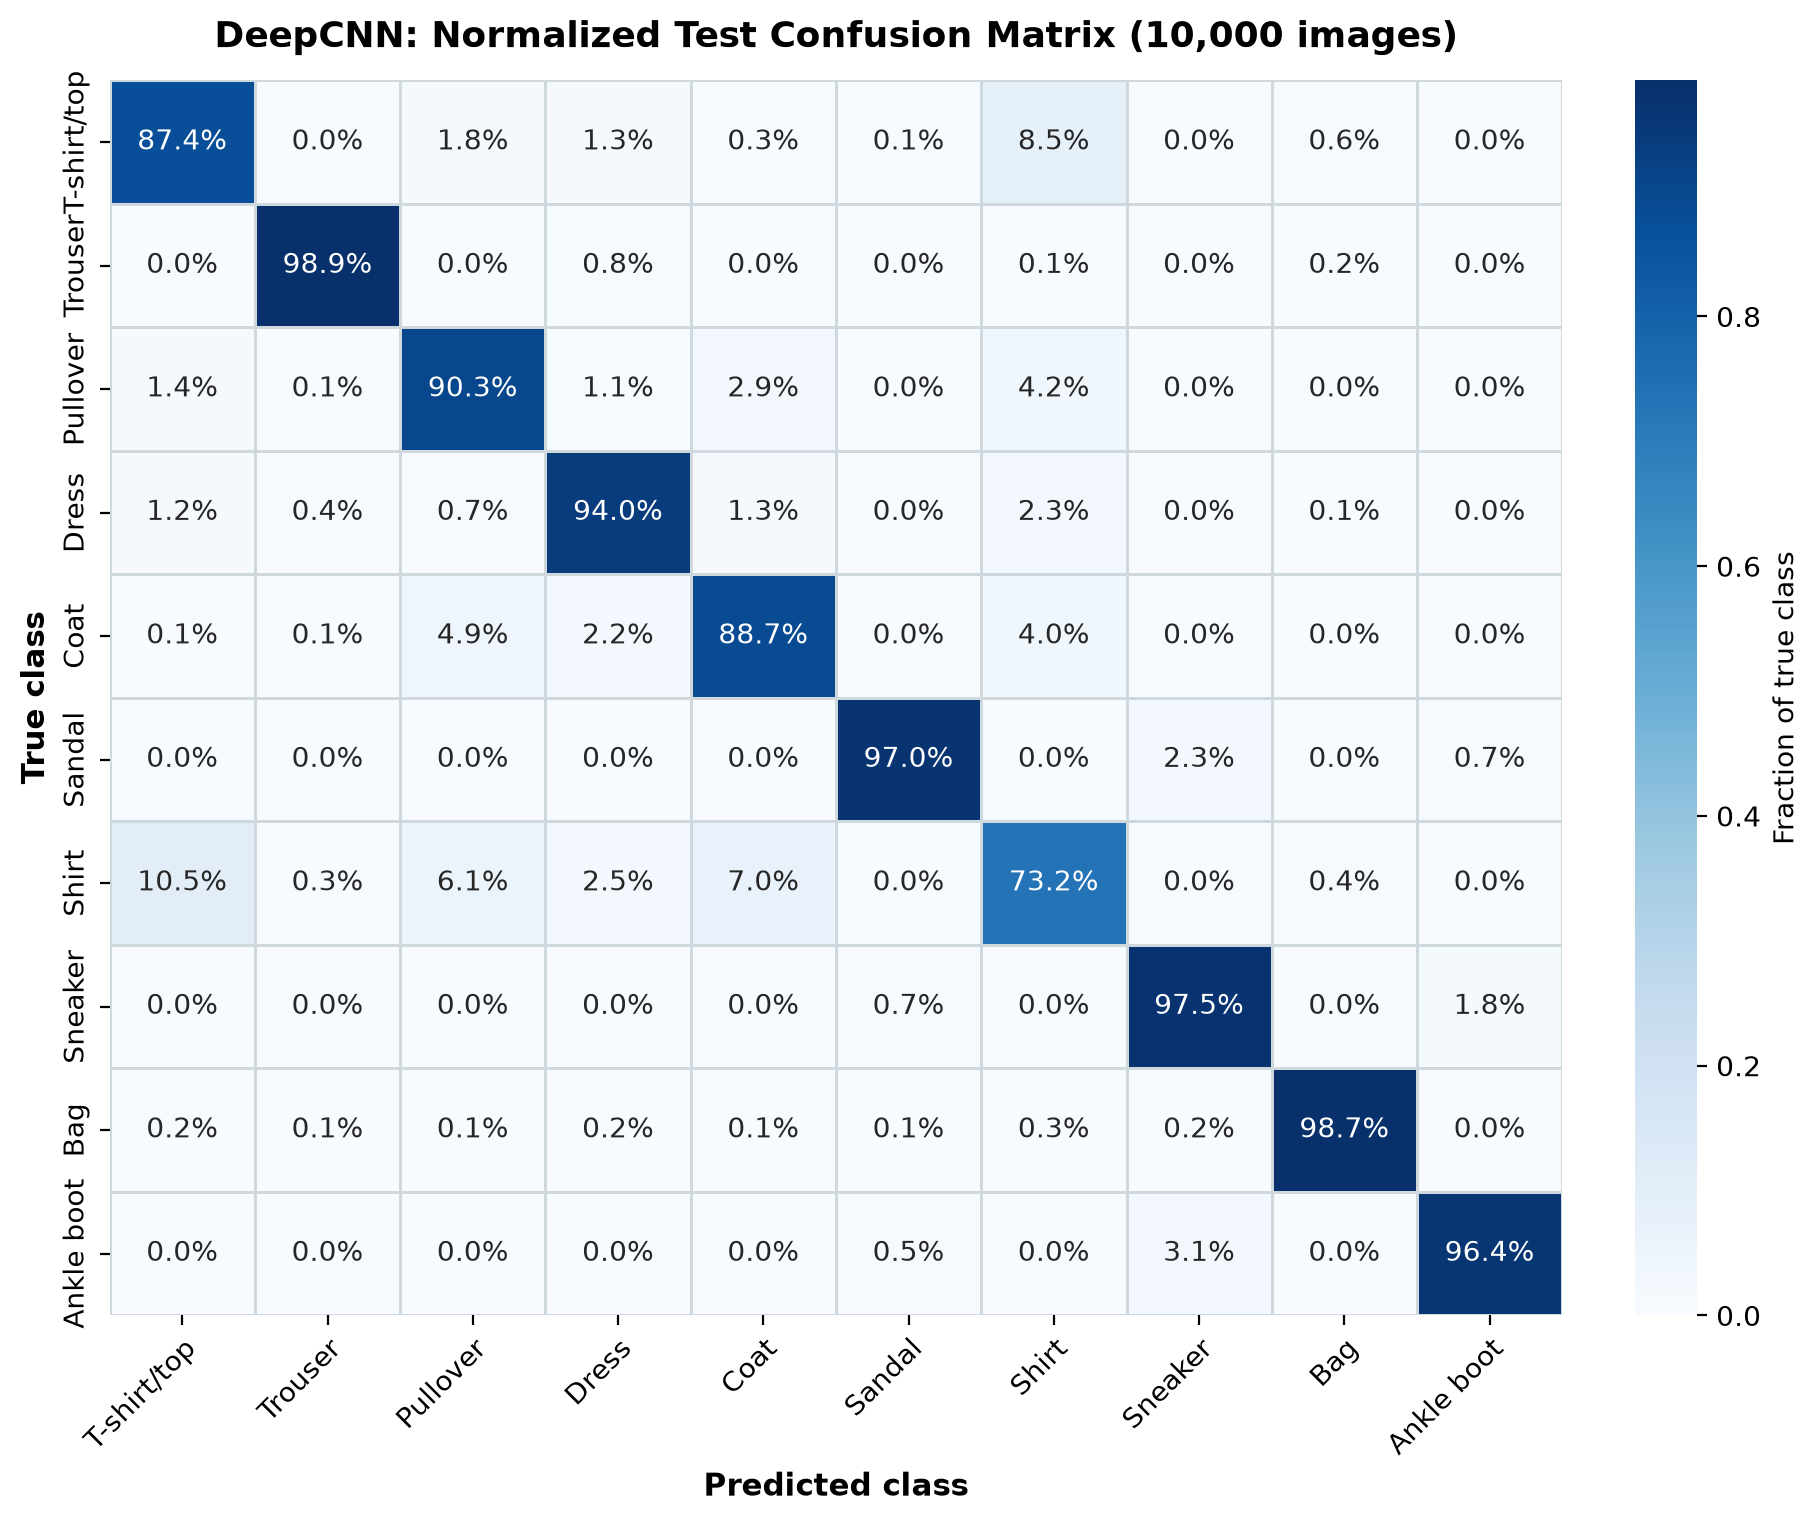

True Shirt images sent to other classes:
T-shirt/top    10.5%
Coat            7.0%
Pullover        6.1%
Dress           2.5%


In [8]:
import seaborn as sns

cm = np.array(experiments["cnn_deep"]["record"]["test_confusion_matrix"])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 7.5), constrained_layout=True)
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax,
    linewidths=0.5,
    linecolor="#CFD8DC",
    cbar_kws={"label": "Fraction of true class"},
)
ax.set_title("DeepCNN: Normalized Test Confusion Matrix (10,000 images)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Predicted class", fontsize=11, fontweight="bold")
ax.set_ylabel("True class", fontsize=11, fontweight="bold")
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", rotation_mode="anchor")

fig.savefig(FIGURES_DIR / "confusion_matrix_deep.png", bbox_inches="tight", dpi=200)
plt.show()

shirt_row = pd.Series(cm_norm[SHIRT], index=CLASS_NAMES).drop("Shirt").sort_values(ascending=False)
print("True Shirt images sent to other classes:")
print(shirt_row.head(4).map("{:.1%}".format).to_string())


## 7. Export result records

In [9]:
for name, exp in experiments.items():
    path = RESULTS_DIR / f"{name}.json"
    path.write_text(json.dumps(exp["record"], indent=2) + "\n")
    print(f"Wrote {path.relative_to(ROOT)}")

Wrote phase2_reports/results/cnn_simple.json
Wrote phase2_reports/results/cnn_deep.json


## 8. Findings

Numbers below are from the run recorded in this notebook (seed 42, Apple MPS). GPU training is not bit-for-bit deterministic, so a rerun can move them by a few tenths of a point.

**1. Both CNNs clearly beat every Phase 1 model.** The best AML baseline was Random Forest on pixels at 87.31% test Macro F1. `SimpleCNN` reaches **91.08%** (+3.8 points) and `DeepCNN` **92.16%** (+4.9 points), with about 0.4M parameters each versus 1.7M tree nodes for the forest.

**2. The third block helps, modestly.** `DeepCNN` is +1.1 points in test accuracy (92.21% vs 91.14%) and Macro F1 over `SimpleCNN`, with *fewer* parameters (390,634 vs 421,738) because the smaller $3 \times 3$ feature map shrinks the dense head. The gain is concentrated in upper-body classes: Pullover +4.1, T-shirt/top +2.7, Shirt +2.3 points of recall. Coat is the one class that drops (-0.6). This is a single seed, so differences of a point or less per class should not be over-read.

**3. Shirt recall improved a lot but did not reach the 80% target.** Phase 1 Shirt recall was 50.7%–62.6%. `SimpleCNN` gets **70.9%** and `DeepCNN` **73.2%**, about 10 points above the best Phase 1 model (k-NN on HOG, 62.6%) but short of the $\ge 80\%$ goal in the Phase 2 plan. In the `DeepCNN` confusion matrix, 26.1% of true Shirts are still sent to the other upper-body classes: T-shirt/top 10.5%, Coat 7.0%, Pullover 6.1%, Dress 2.5%. The upper-body bottleneck is reduced, not resolved.

**4. No overfitting, and training had not finished converging.** Neither run triggered early stopping; both used all 30 epochs, with best validation Macro F1 at epoch 26 (`SimpleCNN`, 92.08%) and epoch 29 (`DeepCNN`, 93.02%). Training accuracy (88.8% / 90.9%) stays *below* validation accuracy throughout, which is the expected effect of dropout and augmentation being active only during training (see the note in Section 1), not a sign of leakage. Validation loss was still falling slowly for `DeepCNN` at epoch 30, so a larger epoch budget would probably give a small further gain.

**5. Cost.** Training took about 4 minutes per model on MPS. Batched inference is about 0.024–0.029 ms per image on MPS, the same order as Random Forest on CPU; this is not a like-for-like hardware comparison with the Phase 1 latencies.

**Exports:** `phase2_reports/results/cnn_simple.json`, `cnn_deep.json` (Phase 1 schema plus per-epoch `history`), and `phase2_reports/figures/training_curves_simple.png`, `training_curves_deep.png`, `confusion_matrix_deep.png`.
